# Optimización de portafolios con riskfolio

In [1]:
# %pip install --quiet riskfolio-lib ffn

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import riskfolio as rp
import ffn
import re

In [3]:
# Definamos algunos de los parametros que vamos a emplear

empresas = pd.read_csv(filepath_or_buffer = "https://raw.githubusercontent.com/salas317/Data/main/NASDAQ_NYSE.csv",
                       parse_dates = ["IPO Date"],
                       dayfirst = True)
acciones = empresas["Ticker Symbol"][0:21].to_list()
acciones = [re.sub(pattern = r"[\.\ ]", repl = "-", string = accion) for accion in acciones]
start_date = "2019-01-01"
end_date = "2026-10-20"
rf_annual = 0.119
alpha = 0.05

# Conversión a tasa diaria
rf_daily = (1 + rf_annual)**(1/252) - 1

## Descarga de los datos

Vamos a descargar los precios de las acciones y a calcular los retornos.

In [4]:
prices = yf.download(
    acciones,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)["Adj Close"]

In [5]:
returns = prices.to_log_returns().dropna()
returns.head()

Ticker,AAPL,AMAT,AMD,AMZN,AVGO,BRK-A,COST,CSCO,CVX,GOOGL,...,JNJ,JPM,LLY,MA,MSFT,MU,NVDA,ORCL,V,WMT
Date,,,,,,,,,,,,,,,,,,,,,
2019-01-03,-0.104924,-0.059692,-0.099301,-0.025566,-0.093159,-0.057733,-0.021423,-0.037046,-0.019338,-0.028086,...,-0.016018,-0.014314,-0.031569,-0.046164,-0.037482,-0.054916,-0.062319,-0.009778,-0.036702,-0.005156
2019-01-04,0.041803,0.066241,0.108289,0.048851,0.009781,0.018982,0.028625,0.044060,0.020512,0.050021,...,0.016644,0.036202,0.029652,0.046269,0.045460,0.053388,0.062099,0.042197,0.042179,0.006227
2019-01-07,-0.002229,0.017647,0.079395,0.033777,0.020161,0.009866,0.003678,0.006734,0.012910,-0.001996,...,-0.006436,0.000695,0.005393,0.007664,0.001275,0.038985,0.051587,0.015718,0.017872,0.011703
2019-01-08,0.018884,-0.041369,0.008713,0.016476,-0.008058,-0.003731,0.007460,0.008068,-0.004374,0.008745,...,0.022961,-0.001888,0.009153,0.007255,0.007224,-0.007676,-0.025211,0.009022,0.005424,0.006957
2019-01-09,0.016839,0.041369,-0.027359,0.001713,0.042340,0.000883,0.006453,-0.005525,0.013331,-0.003433,...,-0.007957,-0.001692,0.007450,0.017988,0.014198,0.049157,0.019476,-0.002091,0.011700,-0.003262


## Funciones de desempeño

Vamos a crear varias funciones que nos permitan calcular la entropía de un portafolio y también sus metricas.

In [6]:
def shannon_entropy(weights):
    w = np.array(weights).flatten()
    w = np.clip(np.abs(w), 1e-12, None)
    w = w / w.sum()
    return -np.sum(w * np.log(w))

def portfolio_metrics(weights, returns, rf=0):
    w = np.array(weights).reshape(-1, 1)
    port_rets = returns @ w
    mu = port_rets.mean().item() * 252
    vol = port_rets.std().item() * np.sqrt(252)
    sharpe = (mu - rf) / vol if vol > 0 else np.nan
    ent = shannon_entropy(w)
    return {"retorno": mu, "riesgo": vol, "sharpe": sharpe, "entropia": ent}

def make_summary(name, w, returns, rf=rf_annual):
    metrics = portfolio_metrics(w.values, returns, rf)
    metrics["modelo"] = name
    return pd.DataFrame([metrics])

## MV con restricción de numero de activos

Ahora, vamos a construir el primer portafolio.

In [7]:
port_mv = rp.Portfolio(
    returns=returns, # Matriz de los retornos estimados de los activos
    sht=False, # Determina si se permiten cortos o no en el portafolio
    upperlng=1.0, # Indica el limite de las posiciones largas
    budget=1.0, # Limite de la suma de los pesos
    alpha=alpha, # La significancia del ES
    nea=5 # Numero mínimo de activos en el portafolio. Por defecto no limita la cantidad de activos.
)
port_mv.assets_stats(method_mu="hist", method_cov="hist") # Se emplea la media histórica y la varianza histórica para hacer la optimización.

# Pero tambien se puede usar metodos exponenciales

# port_mv.assets_stats(method_mu="ewma1", method_cov="ewma1")

Vamos a observar la frontera eficiente de los posibles portafolios:

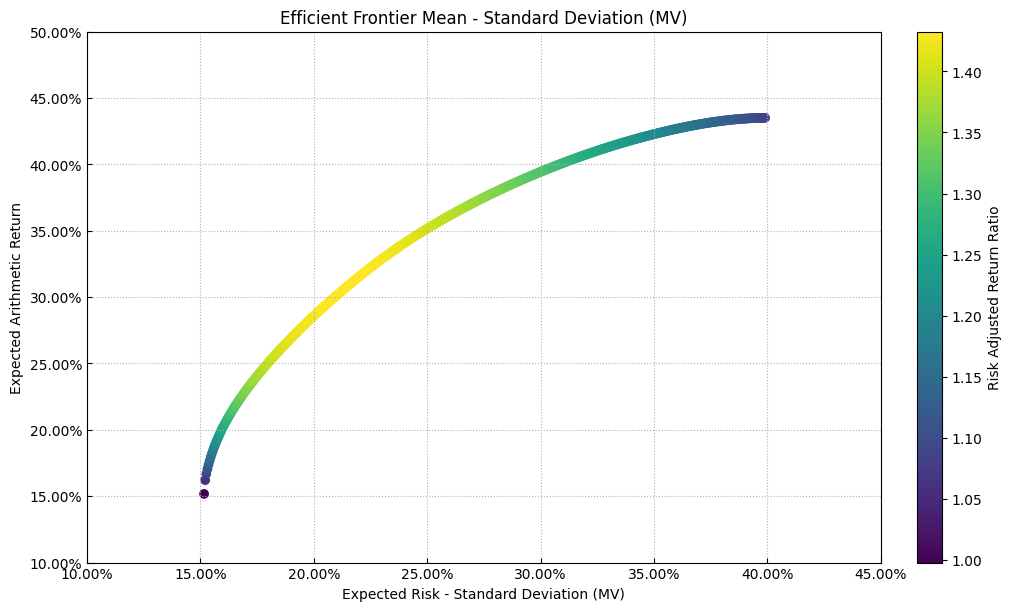

In [8]:
frontier_mv = port_mv.efficient_frontier(model="Classic", 
                                         rm="MV",
                                         points=500,
                                         rf=rf_daily)

ax = rp.plot_frontier(
    w_frontier=frontier_mv,
    mu=port_mv.mu,
    cov=port_mv.cov,
    returns=returns,
    rm="MV",
    rf=rf_daily,
    alpha=alpha,
    cmap="viridis",
    t_factor=252 #  Peridos, 252 anualiza retornos diarios
)

plt.show()

A partir de este objeto `port_mv` se puede generar cuatro portafolios diferentes:

-   Maximizar el retorno.
-   Minimizar el riesgo.
-   Maximizar el RS
-   Maximizar la utilidad cuadrática.

In [9]:
w_mv_maxret = port_mv.optimization(model="Classic", 
                                   rm="MV", 
                                   obj="MaxRet", 
                                   rf=rf_daily) # Retorno

w_mv_minrisk = port_mv.optimization(model="Classic",
                                    rm="MV",
                                    obj="MinRisk",
                                    rf=rf_daily) # Riesgo

w_mv_sharpe = port_mv.optimization(model="Classic",
                                   rm="MV",
                                   obj="Sharpe",
                                   rf=rf_daily) # Sharpe

w_mv_util_2 = port_mv.optimization(model="Classic", # Utilidad cuadrática
                                   rm="MV",
                                   obj="Utility",
                                   rf=rf_daily,
                                   l=2) # l es la aversion al riesgo.

Veamos los resultados de los portafolios:

In [10]:
summary = pd.concat([
    make_summary("MV - Max Return", w_mv_maxret, returns),
    make_summary("MV - Min Risk", w_mv_minrisk, returns),
    make_summary("MV - Max Sharpe", w_mv_sharpe, returns),
    make_summary("MV - Max QU", w_mv_util_2, returns),
], ignore_index=True)

summary = summary[["modelo", "retorno", "riesgo", "sharpe", "entropia"]]
summary

,modelo,retorno,riesgo,sharpe,entropia
0,MV - Max Return,0.435049,0.399027,0.792049,1.746189
1,MV - Min Risk,0.151739,0.151606,0.215947,1.848130
2,MV - Max Sharpe,0.361126,0.259543,0.932895,1.788877
3,MV - Max QU,0.354686,0.253003,0.931558,1.774261


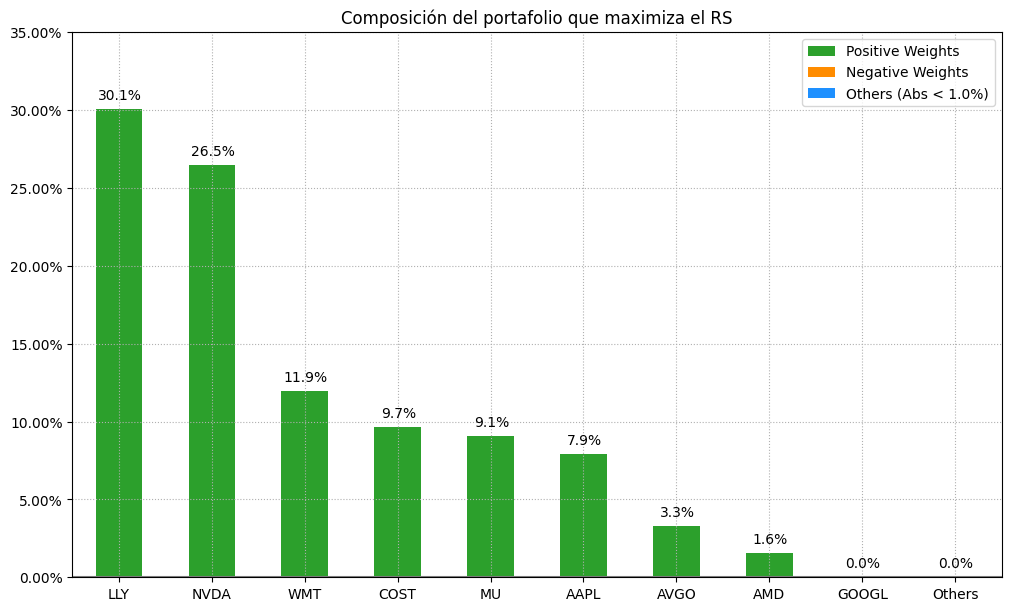

In [11]:
rp.plot_bar(w = w_mv_sharpe,
            title="Composición del portafolio que maximiza el RS")
plt.show()

## Optimización con CVaR como medida de riesgo

In [12]:
port_cvar = rp.Portfolio(
    returns=returns,
    sht=False,
    upperlng=1.0,
    budget=1.0,
    alpha=alpha,
    nea=5
)
port_cvar.assets_stats(method_mu="hist", method_cov="hist")

In [13]:
w_cvar_maxret = port_cvar.optimization(model="Classic", rm="CVaR", obj="MaxRet", rf=rf_daily)
w_cvar_minrisk = port_cvar.optimization(model="Classic", rm="CVaR", obj="MinRisk", rf=rf_daily)
w_cvar_sharpe = port_cvar.optimization(model="Classic", rm="CVaR", obj="Sharpe", rf=rf_daily)
w_cvar_util_2 = port_cvar.optimization(model="Classic", rm="CVaR", obj="Utility", rf=rf_daily, l=2)

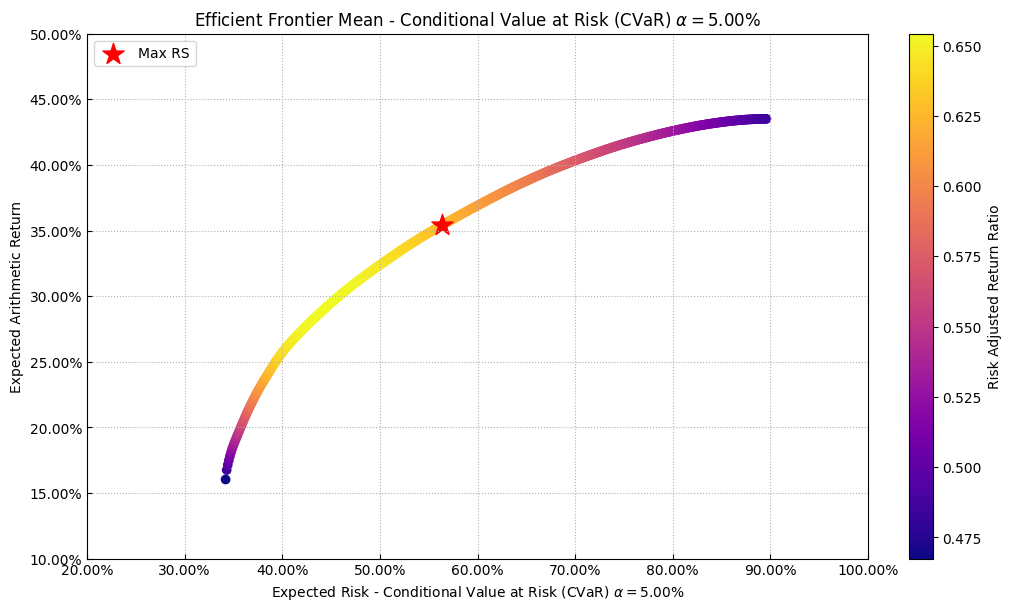

In [14]:
frontier_cvar = port_cvar.efficient_frontier(model="Classic", rm="CVaR", points=500, rf=rf_daily)

ax = rp.plot_frontier(
    w_frontier=frontier_cvar,
    mu=port_cvar.mu,
    cov=port_cvar.cov,
    returns=returns,
    rm="CVaR",
    rf=rf_daily,
    alpha=alpha,
    cmap="plasma",
    w=w_cvar_sharpe,
    label="Max RS"
)
plt.show()

## Optimización con apalancamiento

Vamos a permitir la optimización con posiciones en corto. Sin embargo vamos a limitar el máximo apalancamiento a un 30%.

In [15]:
port_mv_lev = rp.Portfolio(
    returns=returns,
    sht=True, #permite los cortos
    upperlng=1.0,
    uppersht=0.05, # Máximo pesos en corto de un activo
    budget=1.0,
    budgetsht=0.30, # Valor maximo de la suma de los absolutos de los cortos.
    alpha=alpha,
    nea=5
)
port_mv_lev.assets_stats(method_mu="hist", method_cov="hist")

w_mv_lev_sharpe = port_mv_lev.optimization(model="Classic", rm="MV", obj="Sharpe", rf=rf_daily)

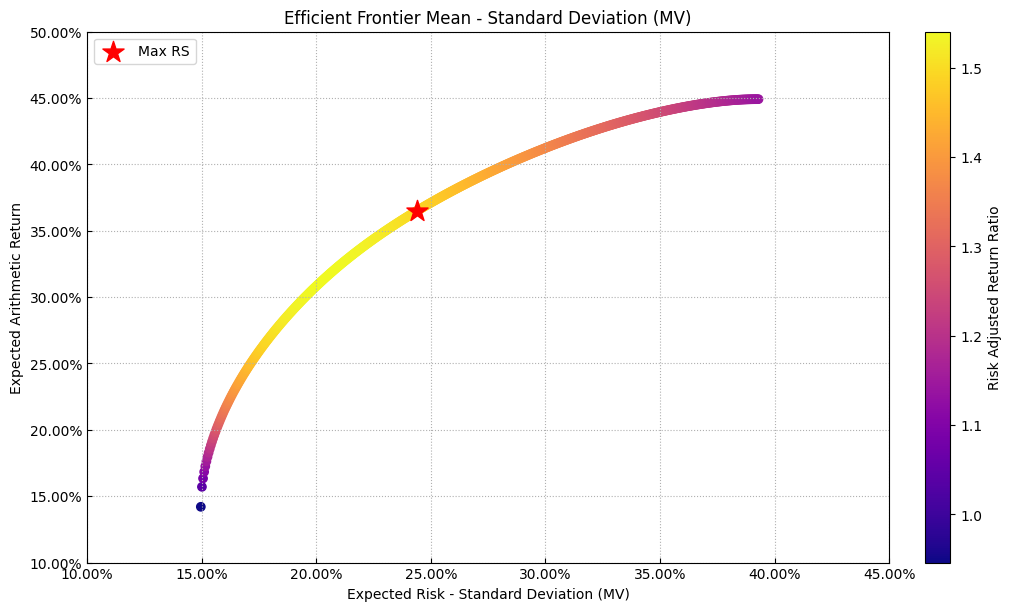

In [16]:
frontier_mv_lev = port_mv_lev.efficient_frontier(model="Classic", rm="MV", points=500, rf=rf_daily)

ax = rp.plot_frontier(
    w_frontier=frontier_mv_lev,
    mu=port_mv_lev.mu,
    cov=port_mv_lev.cov,
    returns=returns,
    rm="MV",
    rf=rf_daily,
    alpha=alpha,
    cmap="plasma",
    w=w_mv_lev_sharpe,
    label="Max RS"
)
plt.show()

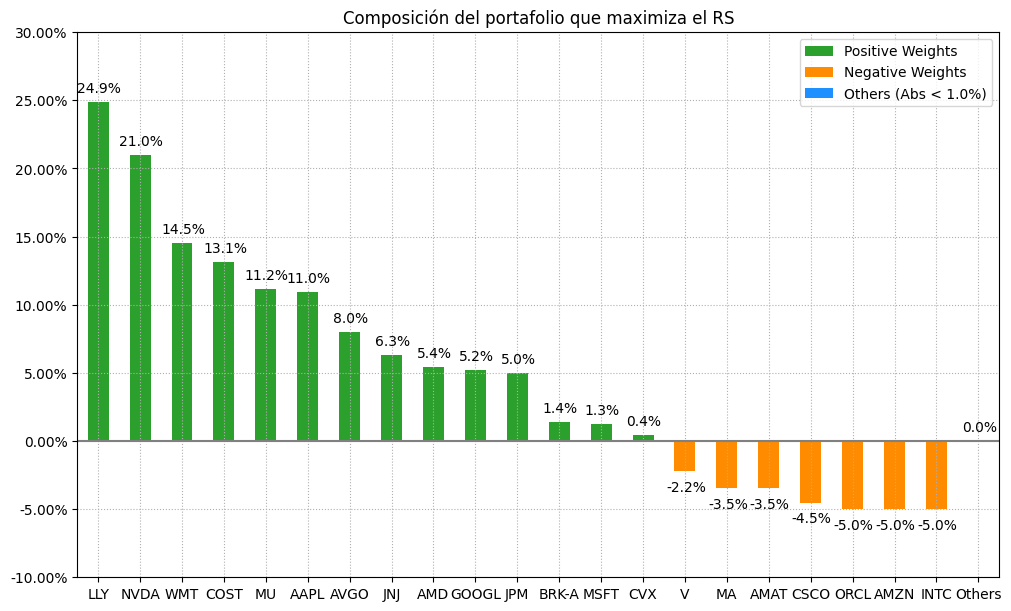

In [17]:
rp.plot_bar(w = w_mv_lev_sharpe,
            title="Composición del portafolio que maximiza el RS")
plt.show()

In [18]:
port_cvar_lev = rp.Portfolio(
    returns=returns,
    sht=True,
    upperlng=1.0,
    uppersht=0.05,
    budget=1.0,
    budgetsht=0.30,
    alpha=alpha,
    nea=5
)
port_cvar_lev.assets_stats(method_mu="hist", method_cov="hist")

w_cvar_lev_sharpe = port_cvar_lev.optimization(model="Classic", rm="CVaR", obj="Sharpe", rf=rf_daily)

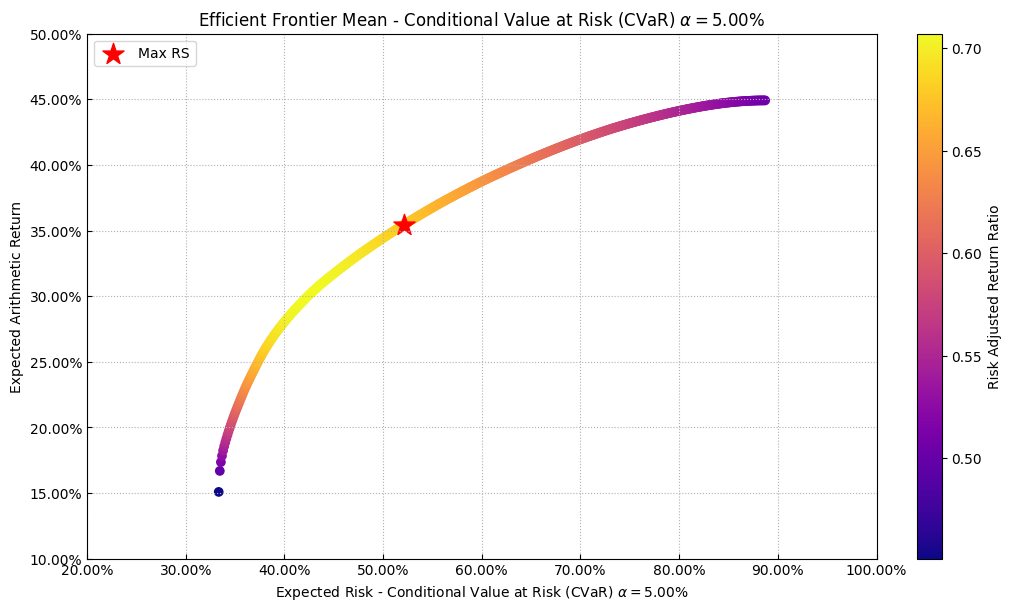

In [19]:
frontier_cvar_lev = port_cvar_lev.efficient_frontier(model="Classic", rm="CVaR", points=500, rf=rf_daily)

ax = rp.plot_frontier(
    w_frontier=frontier_cvar_lev,
    mu=port_cvar_lev.mu,
    cov=port_cvar_lev.cov,
    returns=returns,
    rm="CVaR",
    rf=rf_daily,
    alpha=alpha,
    cmap="plasma",
    w=w_cvar_lev_sharpe,
    label="Max RS"
)
plt.show()

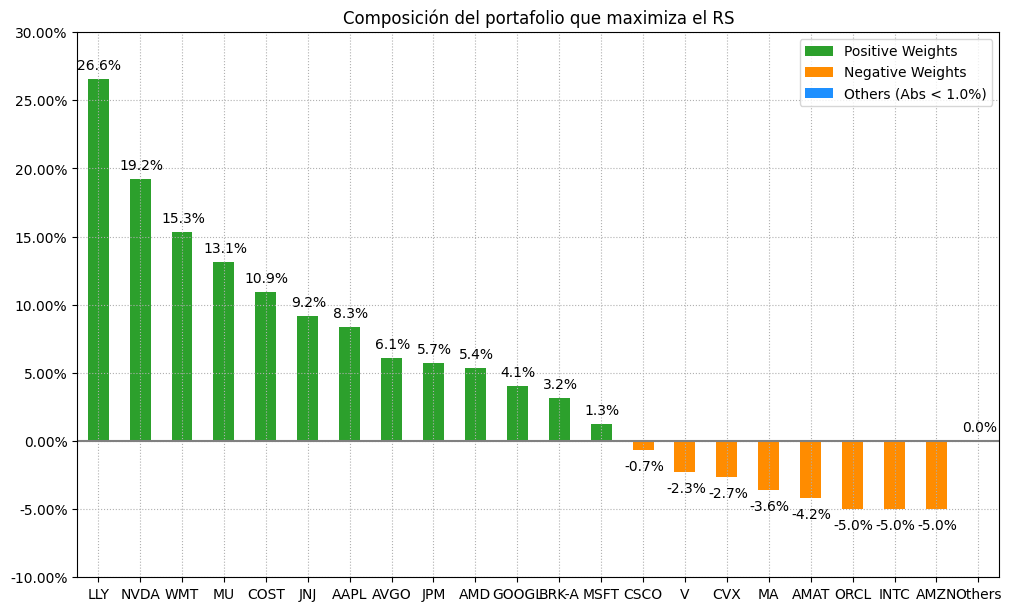

In [20]:
rp.plot_bar(w = w_cvar_lev_sharpe,
            title="Composición del portafolio que maximiza el RS")
plt.show()

## Maximizar la utilidad cuadrática para diferentes valores de la aversión al riesgo

In [21]:
risk_aversions = [0.5, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
utility_results = []

for lmbda in risk_aversions:
    w = port_mv.optimization(model="Classic", rm="MV", obj="Utility", rf=rf_daily, l=lmbda)
    m = portfolio_metrics(w.values, returns, rf_annual)
    m["lambda"] = lmbda
    utility_results.append(m)

utility_df = pd.DataFrame(utility_results)
utility_df

,retorno,riesgo,sharpe,entropia,lambda
0,0.427472,0.361804,0.852595,1.754814,0.5
1,0.403706,0.314009,0.906682,1.809323,1.0
2,0.354686,0.253003,0.931558,1.774261,2.0
3,0.320373,0.223572,0.900705,1.755649,3.0
4,0.285246,0.199611,0.832853,1.908775,4.0
5,0.259572,0.184654,0.761274,2.024385,5.0
6,0.240983,0.175181,0.696325,2.033893,6.0
7,0.227895,0.169301,0.643202,2.019056,7.0
8,0.218115,0.165387,0.599293,1.987936,8.0
9,0.210699,0.162718,0.563544,1.974204,9.0


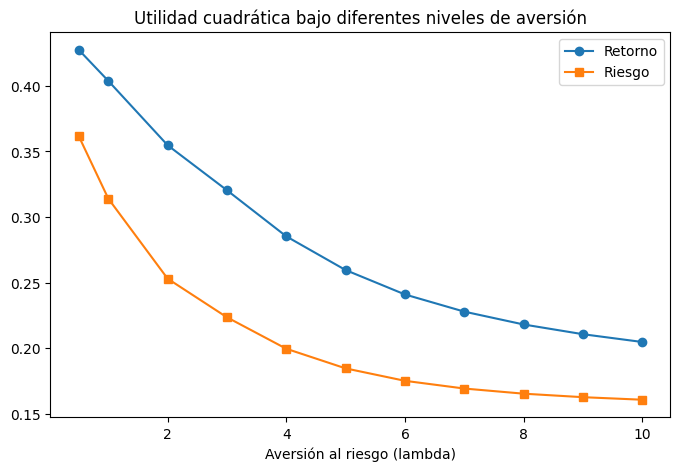

In [22]:
plt.figure(figsize=(8,5))
plt.plot(utility_df["lambda"], utility_df["retorno"], marker="o", label="Retorno")
plt.plot(utility_df["lambda"], utility_df["riesgo"], marker="s", label="Riesgo")
plt.xlabel("Aversión al riesgo (lambda)")
plt.title("Utilidad cuadrática bajo diferentes niveles de aversión")
plt.legend()
plt.show()

## Cuadro resumen

In [23]:
summary = pd.concat([
    make_summary("MV - Max Sharpe", w_mv_sharpe, returns),
    make_summary("CVaR - Max Sharpe", w_cvar_sharpe, returns),
    make_summary("MV apalancado - Max Sharpe", w_mv_lev_sharpe, returns),
    make_summary("CVaR apalancado - Max Sharpe", w_cvar_lev_sharpe, returns)
], ignore_index=True)

summary = summary[["modelo", "retorno", "riesgo", "sharpe", "entropia"]]
summary.sort_values("sharpe", ascending=False)

,modelo,retorno,riesgo,sharpe,entropia
2,MV apalancado - Max Sharpe,0.365071,0.244008,1.008454,2.735743
3,CVaR apalancado - Max Sharpe,0.354567,0.236023,0.998069,2.743488
0,MV - Max Sharpe,0.361126,0.259543,0.932895,1.788877
1,CVaR - Max Sharpe,0.353909,0.253292,0.927424,1.793495
